In [16]:

!pip -q install ucimlrepo


In [17]:

from ucimlrepo import fetch_ucirepo

# Fetch the official UCI dataset
credit_data = fetch_ucirepo(id=350)

X = credit_data.data.features
y = credit_data.data.targets

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

display(X.head())
display(y.head())


Feature data shape: (30000, 23)
Target data shape: (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


,Y
0,1
1,1
2,0
3,0
4,0


In [18]:

# Inspect the dataset's official variable descriptions
print(credit_data.variables[
    ["name", "description", "type"]
].to_string(index=False))


name                description    type
  ID                       None Integer
  X1                  LIMIT_BAL Integer
  X2                        SEX Integer
  X3                  EDUCATION Integer
  X4                   MARRIAGE Integer
  X5                        AGE Integer
  X6                      PAY_0 Integer
  X7                      PAY_2 Integer
  X8                      PAY_3 Integer
  X9                      PAY_4 Integer
 X10                      PAY_5 Integer
 X11                      PAY_6 Integer
 X12                  BILL_AMT1 Integer
 X13                  BILL_AMT2 Integer
 X14                  BILL_AMT3 Integer
 X15                  BILL_AMT4 Integer
 X16                  BILL_AMT5 Integer
 X17                  BILL_AMT6 Integer
 X18                   PAY_AMT1 Integer
 X19                   PAY_AMT2 Integer
 X20                   PAY_AMT3 Integer
 X21                   PAY_AMT4 Integer
 X22                   PAY_AMT5 Integer
 X23                   PAY_AMT6 Integer


In [19]:

import pandas as pd
import numpy as np

# Combine features and target for an initial audit
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Y"].value_counts())

print("\nTarget proportions:")
print((df["Y"].value_counts(normalize=True) * 100).round(2))



Dataset shape: (30000, 24)

Missing values:
0

Duplicate rows: 35

Target distribution:
Y
0    23364
1     6636
Name: count, dtype: int64

Target proportions:
Y
0    77.88
1    22.12
Name: proportion, dtype: float64


In [20]:

# Combine the features and target for investigation
audit_df = X.copy()
audit_df["Y"] = y

# Find all rows whose predictor values are duplicated
duplicate_mask = X.duplicated(keep=False)
duplicate_records = audit_df.loc[duplicate_mask].copy()

print("Rows involved in duplicate feature patterns:",
      len(duplicate_records))

# Display examples, including the target outcome
display(duplicate_records.head(20))

# Check whether identical feature patterns have conflicting target labels
target_conflicts = (
    audit_df.groupby(list(X.columns), dropna=False)["Y"]
    .nunique()
    .gt(1)
    .sum()
)

print("Duplicate feature patterns with conflicting target labels:",
      target_conflicts)


Rows involved in duplicate feature patterns: 108


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
18,360000,2,1,1,49,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
291,50000,2,2,2,22,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
627,230000,1,1,1,39,-1,-1,-1,-1,-1,...,660,660,660,660,660,660,660,660,660,0
839,500000,1,1,1,43,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
881,210000,2,2,1,49,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1093,360000,1,2,1,41,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1211,160000,2,3,2,26,-1,-1,-1,-1,-1,...,390,390,390,390,390,390,390,390,390,0
1601,150000,2,1,1,31,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1759,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1964,150000,2,1,1,38,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1


Duplicate feature patterns with conflicting target labels: 21


Overall default rate: 22.12%


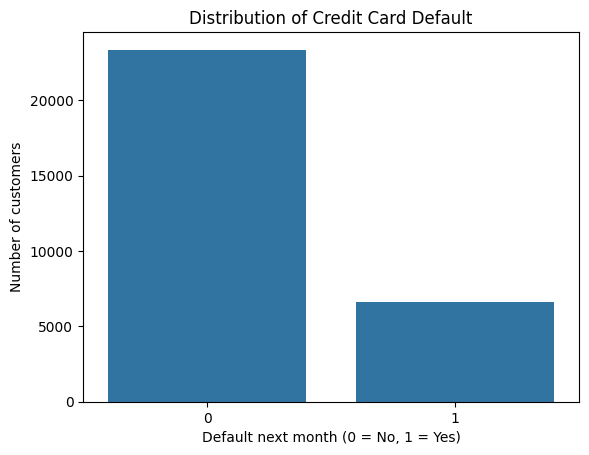


Default rate by X6 repayment status:


,Default rate (%)
X6,
-2,13.23
-1,16.78
0,12.81
1,33.95
2,69.14
3,75.78
4,68.42
5,50.00
6,54.55



Default rate by X7 repayment status:


,Default rate (%)
X7,
-2,18.27
-1,15.97
0,15.91
1,17.86
2,55.61
3,61.66
4,50.51
5,60.00
6,75.00



Default rate by X8 repayment status:


...

,Default rate (%)
X9,
-2,19.25
-1,15.90
0,18.33
1,50.00
2,52.33
3,61.11
4,66.67
5,51.43
6,40.00



Default rate by X10 repayment status:


,Default rate (%)
X10,
-2,19.69
-1,16.19
0,18.85
2,54.19
3,63.48
4,60.71
5,58.82
6,75.00
7,82.76



Default rate by X11 repayment status:


,Default rate (%)
X11,
-2,20.04
-1,16.99
0,18.84
2,50.65
3,64.13
4,63.27
5,53.85
6,73.68
7,82.61


In [21]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert the target to a one-dimensional Series
target = y.squeeze()

# Calculate overall default rate
default_rate = target.mean() * 100
print(f"Overall default rate: {default_rate:.2f}%")

# Plot the target distribution
sns.countplot(x=target)
plt.title("Distribution of Credit Card Default")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.show()

# Examine repayment status patterns
repayment_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

for col in repayment_cols:
    if col in X.columns:
        rate = target.groupby(X[col]).mean() * 100
        print(f"\nDefault rate by {col} repayment status:")
        display(rate.round(2).rename("Default rate (%)"))


Credit limit by default outcome:


,count,mean,median
No default,23364,178099.73,150000.0
Default,6636,130109.66,90000.0


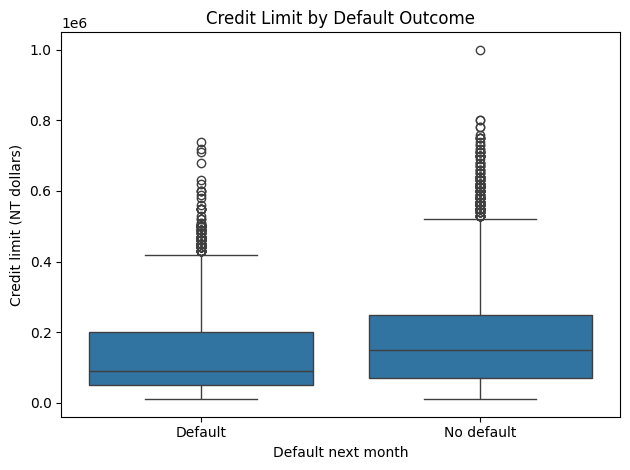

Default rates by most recent repayment status:


,count,default_rate
X6,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


In [22]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the target is a one-dimensional Series
target = y.squeeze()

# 1. Compare credit limits for customers who defaulted
credit_limit = X["X1"]

credit_summary = (
    credit_limit.groupby(target)
    .agg(["count", "mean", "median"])
    .round(2)
)

credit_summary.index = ["No default", "Default"]
print("Credit limit by default outcome:")
display(credit_summary)

# 2. Visualise credit limits by outcome
plot_df = pd.DataFrame({
    "Credit limit": credit_limit,
    "Default outcome": target.map({0: "No default", 1: "Default"})
})

sns.boxplot(data=plot_df, x="Default outcome", y="Credit limit")
plt.title("Credit Limit by Default Outcome")
plt.xlabel("Default next month")
plt.ylabel("Credit limit (NT dollars)")
plt.tight_layout()
plt.show()

# 3. Examine repayment status for the most recent recorded month
recent_status = (
    target.groupby(X["X6"])
    .agg(["count", "mean"])
    .rename(columns={"mean": "default_rate"})
)

recent_status["default_rate"] = recent_status["default_rate"] * 100

print("Default rates by most recent repayment status:")
display(recent_status.round(2))


In [23]:

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Make sure the target is one-dimensional
target = y.squeeze().astype(int)

# Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, target,
    test_size=0.2,
    random_state=42,
    stratify=target
)

# Define the models
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced")
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate each model
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    if hasattr(model, "predict_proba"):
        row["ROC-AUC"] = roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )

    results.append(row)

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Baseline,0.779,0.000,0.000,0.000,0.500
Logistic Regression,0.680,0.367,0.620,0.461,0.708
Random Forest,0.812,0.640,0.342,0.446,0.760



Logistic Regression
              precision    recall  f1-score   support

  No Default       0.87      0.70      0.77      4673
     Default       0.37      0.62      0.46      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.70      6000



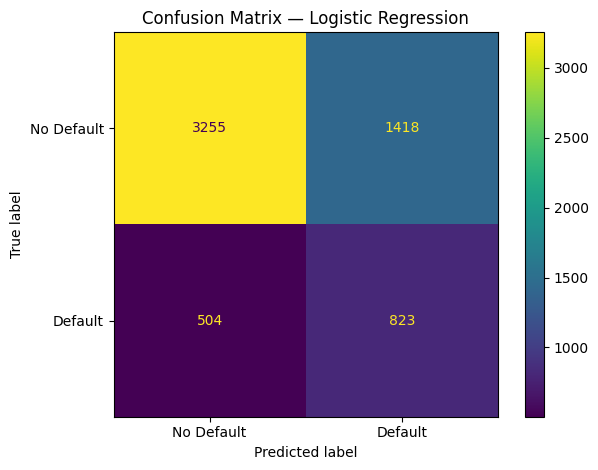


Random Forest
              precision    recall  f1-score   support

  No Default       0.84      0.95      0.89      4673
     Default       0.64      0.34      0.45      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.64      0.67      6000
weighted avg       0.79      0.81      0.79      6000



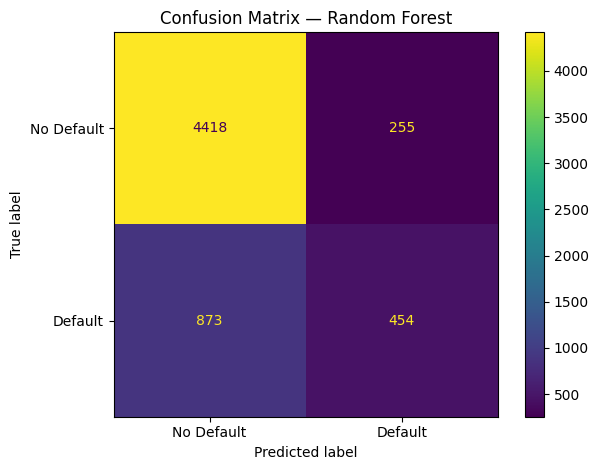

In [24]:

from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

for name in ["Logistic Regression", "Random Forest"]:
    model = models[name]
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions,
        target_names=["No Default", "Default"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["No Default", "Default"],
        values_format="d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()



In [25]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for name in ["Logistic Regression", "Random Forest"]:
    model = models[name]

    # Probability that the customer belongs to class 1 (default)
    default_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_test)[:, default_index]

    for threshold in [0.30, 0.40, 0.50, 0.60]:
        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Customers Flagged": int(predictions.sum())
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(3).sort_values(
        ["Model", "Threshold"]
    ).reset_index(drop=True)
)


,Model,Threshold,Precision,Recall,F1 Score,Customers Flagged
0,Logistic Regression,0.3,0.244,0.888,0.383,4820
1,Logistic Regression,0.4,0.277,0.775,0.408,3721
2,Logistic Regression,0.5,0.367,0.620,0.461,2241
3,Logistic Regression,0.6,0.558,0.449,0.497,1069
4,Random Forest,0.3,0.510,0.528,0.519,1372
5,Random Forest,0.4,0.581,0.435,0.497,993
6,Random Forest,0.5,0.640,0.349,0.451,724
7,Random Forest,0.6,0.705,0.254,0.373,478


Top 10 features used by the Random Forest:


,Feature,Importance
5,X6,0.0982
0,X1,0.0642
4,X5,0.0624
11,X12,0.0617
12,X13,0.0535
17,X18,0.0525
18,X19,0.0518
13,X14,0.0511
14,X15,0.0493
16,X17,0.0487


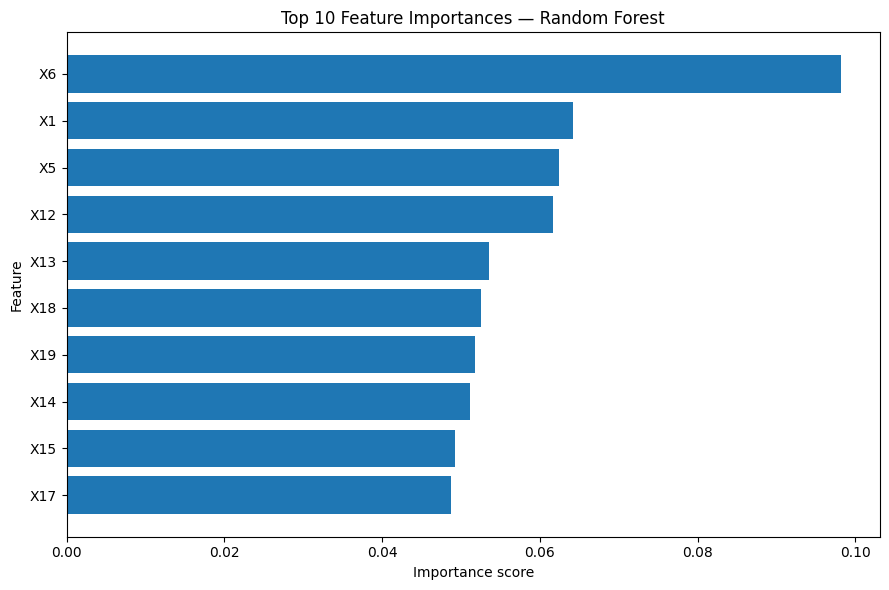

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained Random Forest
rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 10 features used by the Random Forest:")
display(importance_df.head(10).round(4))

# Visualise the top 10
top10 = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Importance score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [27]:

# Final project summary using existing results

print("CREDIT DEFAULT PREDICTION — PROJECT SUMMARY")
print("=" * 50)

print(f"Total records: {len(X)}")
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"Overall default rate: {y.squeeze().mean():.2%}")

print("\nMODEL COMPARISON")
display(results_df.round(3))

print("\nTOP 10 RANDOM FOREST FEATURES")
display(importance_df.head(10).round(4))

print("\nBEST F1 THRESHOLD COMBINATIONS")
display(
    threshold_df.sort_values(
        "F1 Score", ascending=False
    ).head(5).round(3)
)


CREDIT DEFAULT PREDICTION — PROJECT SUMMARY
Total records: 30000
Training records: 24000
Testing records: 6000
Overall default rate: 22.12%

MODEL COMPARISON


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Baseline,0.779,0.000,0.000,0.000,0.500
Logistic Regression,0.680,0.367,0.620,0.461,0.708
Random Forest,0.812,0.640,0.342,0.446,0.760



TOP 10 RANDOM FOREST FEATURES


,Feature,Importance
5,X6,0.0982
0,X1,0.0642
4,X5,0.0624
11,X12,0.0617
12,X13,0.0535
17,X18,0.0525
18,X19,0.0518
13,X14,0.0511
14,X15,0.0493
16,X17,0.0487



BEST F1 THRESHOLD COMBINATIONS


,Model,Threshold,Precision,Recall,F1 Score,Customers Flagged
4,Random Forest,0.3,0.510,0.528,0.519,1372
3,Logistic Regression,0.6,0.558,0.449,0.497,1069
5,Random Forest,0.4,0.581,0.435,0.497,993
2,Logistic Regression,0.5,0.367,0.620,0.461,2241
6,Random Forest,0.5,0.640,0.349,0.451,724


## Findings and Business Recommendations

### Key Findings

1. The dataset contained 30,000 customer records, with no missing values identified during the initial data-quality check. The default rate was 22.12%, indicating an imbalanced classification problem.

2. The baseline model achieved 77.9% accuracy but failed to identify any defaulters, demonstrating why accuracy alone is insufficient for evaluating credit-risk models.

3. Logistic Regression achieved 62.0% recall at the default 0.5 threshold, identifying more actual defaulters than Random Forest at the same threshold. However, it also produced more false positives.

4. Random Forest achieved a ROC-AUC of 0.760, compared with 0.708 for Logistic Regression, indicating stronger overall ranking performance on the test set.

5. Among the eight model-threshold combinations tested, Random Forest at a threshold of 0.30 achieved the highest F1 score of 0.519, with 51.0% precision and 52.8% recall.

6. Feature-importance analysis ranked repayment status for the most recent recorded month (X6) as the most influential feature in the Random Forest, followed by credit limit (X1) and age (X5).

### Business Recommendations

- Use repayment history and other relevant financial information to support credit-risk assessment rather than relying on a single feature.
- Evaluate classification thresholds against the financial cost of missed defaults, unnecessary reviews, and the institution's operational capacity.
- Treat model predictions as decision-support signals for further assessment, not as automatic grounds for rejecting credit applications.
- Assess model fairness, explainability, stability, and performance on more recent, locally representative data before considering operational use.
- Investigate model performance over time and monitor changes in prediction quality before any deployment.

### Limitations

- The dataset contains historical credit-card customer records from Taiwan and may not represent present-day Nigerian banking customers.
- The models identify statistical associations, not causal relationships.
- Feature importance does not establish that a variable causes default.
- The threshold comparison is an initial experiment; the selected threshold has not been validated against a formal business-cost function.
- No model should be deployed for real credit decisions without appropriate validation, governance, fairness assessment, and domain oversight.
